PyTorch version: 2.11.0+cpu
Using device: cpu


100%|██████████| 170M/170M [06:07<00:00, 464kB/s]


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 74.7MB/s]



===== VGG =====
Epoch 1/2 - Train Accuracy: 24.50% - Validation Accuracy: 51.00%
Epoch 2/2 - Train Accuracy: 61.25% - Validation Accuracy: 61.00%
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 163MB/s]



===== RESNET =====
Epoch 1/2 - Train Accuracy: 26.50% - Validation Accuracy: 44.00%
Epoch 2/2 - Train Accuracy: 93.25% - Validation Accuracy: 72.00%
Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 108MB/s]
/usr/local/lib/python3.13/dist-packages/torchvision/models/googlenet.py:341: UserWarning: auxiliary heads in the pretrained googlenet model are NOT pretrained, so make sure to train them
  warnings.warn(



===== GOOGLENET =====
Epoch 1/2 - Train Accuracy: 18.25% - Validation Accuracy: 36.00%
Epoch 2/2 - Train Accuracy: 74.75% - Validation Accuracy: 61.00%

===== FINAL RESULTS =====
VGG        Final Train Accuracy: 61.25% | Final Validation Accuracy: 61.00%
RESNET     Final Train Accuracy: 93.25% | Final Validation Accuracy: 72.00%
GOOGLENET  Final Train Accuracy: 74.75% | Final Validation Accuracy: 61.00%


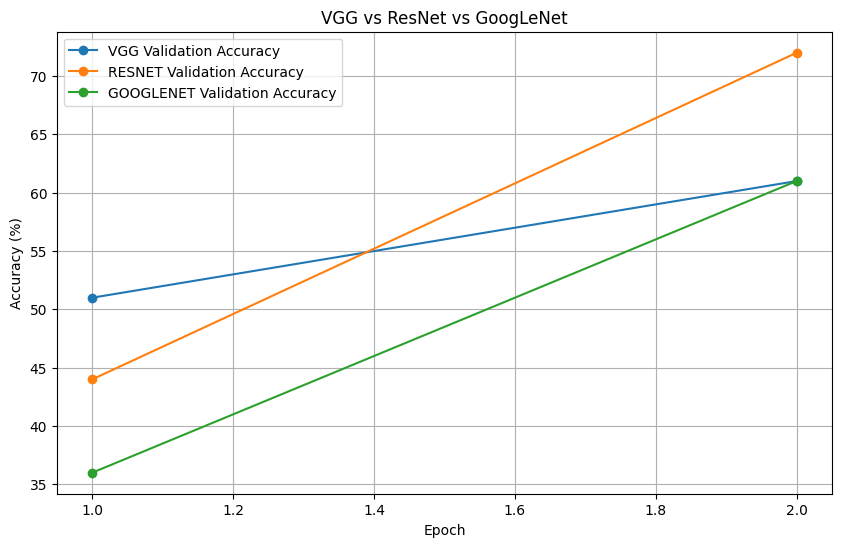


Best model based on validation accuracy: RESNET
Validation Accuracy: 72.00%

Experiment 5 completed successfully.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets
from torchvision import models
from torchvision import transforms

from torch.utils.data import DataLoader
from torch.utils.data import random_split
from torch.utils.data import Subset

import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)


class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]


transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])


dataset = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)


# Use 500 images as in the lab manual
dataset = Subset(
    dataset,
    range(500)
)


train_size = int(
    0.8 * len(dataset)
)

val_size = len(dataset) - train_size


train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size]
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)


val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)


def create_model(name):

    if name == "vgg":

        model = models.vgg16(
            weights=models.VGG16_Weights.DEFAULT
        )

        model.classifier[6] = nn.Linear(
            4096,
            10
        )

    elif name == "resnet":

        model = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            10
        )

    elif name == "googlenet":

        model = models.googlenet(
            weights=models.GoogLeNet_Weights.DEFAULT,
            aux_logits=True
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            10
        )

    else:

        raise ValueError(
            "Unknown model name"
        )

    return model


def train_and_evaluate(
    model,
    name,
    epochs=2
):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.0001
    )

    train_accuracies = []
    val_accuracies = []

    print(
        f"\n===== {name} ====="
    )

    for epoch in range(epochs):

        model.train()

        correct = 0
        total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            if isinstance(outputs, tuple):
                outputs = outputs[0]

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()

            optimizer.step()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

        train_accuracy = (
            100 * correct / total
        )

        train_accuracies.append(
            train_accuracy
        )


        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for inputs, labels in val_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)

                if isinstance(outputs, tuple):
                    outputs = outputs[0]

                _, predicted = torch.max(
                    outputs,
                    1
                )

                total += labels.size(0)

                correct += (
                    predicted == labels
                ).sum().item()

        val_accuracy = (
            100 * correct / total
        )

        val_accuracies.append(
            val_accuracy
        )

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Train Accuracy: "
            f"{train_accuracy:.2f}% "
            f"- Validation Accuracy: "
            f"{val_accuracy:.2f}%"
        )

    return (
        model,
        train_accuracies,
        val_accuracies
    )


results = {}

trained_models = {}


for model_name in [
    "vgg",
    "resnet",
    "googlenet"
]:

    model = create_model(
        model_name
    )

    trained_model, train_acc, val_acc = train_and_evaluate(
        model,
        model_name.upper(),
        epochs=2
    )

    results[model_name] = (
        train_acc,
        val_acc
    )

    trained_models[model_name] = trained_model


print("\n===== FINAL RESULTS =====")

for name, values in results.items():

    train_acc = values[0]

    val_acc = values[1]

    print(
        f"{name.upper():10s} "
        f"Final Train Accuracy: "
        f"{train_acc[-1]:.2f}% "
        f"| Final Validation Accuracy: "
        f"{val_acc[-1]:.2f}%"
    )


plt.figure(figsize=(10, 6))

for name, values in results.items():

    train_acc = values[0]

    val_acc = values[1]

    plt.plot(
        range(1, len(val_acc) + 1),
        val_acc,
        marker="o",
        label=f"{name.upper()} Validation Accuracy"
    )

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title(
    "VGG vs ResNet vs GoogLeNet"
)

plt.legend()

plt.grid(True)

plt.show()


best_model = max(
    results,
    key=lambda name: results[name][1][-1]
)

print(
    f"\nBest model based on validation accuracy: "
    f"{best_model.upper()}"
)

print(
    f"Validation Accuracy: "
    f"{results[best_model][1][-1]:.2f}%"
)


print("\nExperiment 5 completed successfully.")